<a href="https://colab.research.google.com/github/sandesh0shinde/sms-spam-detection/blob/main/email_spam_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Email Spam Detection Using Machine Learning

## 1. Introduction

Email Spam Detection is a Machine Learning project that identifies whether a message is spam or not spam.

Spam messages are unwanted messages that may contain advertisements, fake offers, or suspicious links. These messages can waste time and sometimes create security risks.

In this project, I will train a Machine Learning model to classify messages into two categories: Spam and Not Spam.

This project will help me understand text processing, data analysis, classification, and model evaluation using Python.


## 2. Objectives

The main objectives of this project are:

- To collect a dataset containing spam and non-spam messages.
- To understand and analyze the dataset.
- To clean and prepare the text messages.
- To train a Machine Learning classification model.
- To evaluate the model's performance.
- To predict whether a new message is spam or not spam.

## 3. Importing Libraries

In this step, I import the Python libraries required for the project. These libraries help me manage the dataset, process text messages, train the Machine Learning model, and evaluate its performance.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

## 4. Dataset Collection

In this project, I use the SMS Spam Collection dataset. It contains text messages labeled as spam or ham (not spam).

The dataset helps the Machine Learning model learn the difference between unwanted messages and normal messages.

I use this dataset to train and test a model that can classify messages into spam and not spam categories.

Dataset source: UCI Machine Learning Repository.

In [4]:
import urllib.request
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

# Download and extract the specific file from the ZIP
with urllib.request.urlopen(url) as response:
    with zipfile.ZipFile(io.BytesIO(response.read())) as z:
        with z.open('SMSSpamCollection') as f:
            df = pd.read_csv(f, sep='\t', header=None, names=['label', 'message'])

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [7]:
print("Dataset Size: ", df.shape)

Dataset Size:  (5572, 2)


In [8]:
print("Column Names: ", df.columns.to_list())

Column Names:  ['label', 'message']


In [9]:
print("Dataset Info: ", df.info)

Dataset Info:  <bound method DataFrame.info of      label                                            message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...
...    ...                                                ...
5567  spam  This is the 2nd time we have tried 2 contact u...
5568   ham               Will ü b going to esplanade fr home?
5569   ham  Pity, * was in mood for that. So...any other s...
5570   ham  The guy did some bitching but I acted like i'd...
5571   ham                         Rofl. Its true to its name

[5572 rows x 2 columns]>


In [11]:
print("Message counts: ", df['label'].value_counts())

Message counts:  label
ham     4825
spam     747
Name: count, dtype: int64


In [13]:
print("Missing Values: \n", df.isnull().sum())

Missing Values: 
 label      0
message    0
dtype: int64


## 6. Data Visualization

Data visualization helps us understand the dataset using graphs and charts. In this step, I create a bar chart to compare the number of spam and normal messages.

This visualization helps identify which type of message is more common in the dataset.

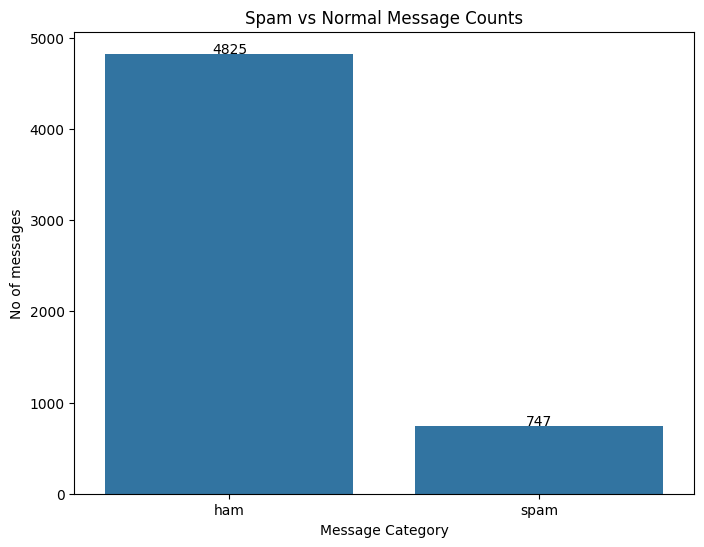

In [56]:
message_counts = df['label'].value_counts()

plt.figure(figsize=(8,6))
sns.barplot(x=message_counts.index, y=message_counts.values)
plt.title("Spam vs Normal Message Counts")
plt.xlabel("Message Category")
plt.ylabel("No of messages")
plt.xticks(rotation=0)

plt.text(
    0,
    message_counts.iloc[0] + 1,
    f"{message_counts.iloc[0]}",
    ha="center"
)

plt.text(
    1,
    message_counts.iloc[1] + 1,
    f"{message_counts.iloc[1]}",
    ha="center"
)

plt.show()

## 7. Data Preparation

In this step, I prepare the dataset for Machine Learning. I separate the text messages from their labels and convert the labels into numerical values.

The message text will be used as input, while the label will be the output that the model learns to predict.

In [36]:
X = df['message']
y = df['label'].map({'ham':0, 'spam': 1})

In [37]:
print("Input Messages: ")
X.head()

Input Messages: 


,message
0,"Go until jurong point, crazy.. Available only ..."
1,Ok lar... Joking wif u oni...
2,Free entry in 2 a wkly comp to win FA Cup fina...
3,U dun say so early hor... U c already then say...
4,"Nah I don't think he goes to usf, he lives aro..."


In [38]:
print("Target Labels: ")
y.head()

Target Labels: 


,label
0,0
1,0
2,1
3,0
4,0


## 8. Data Splitting and Text Vectorization

In this step, I divide the dataset into training data and testing data. The training data is used to teach the model, while the testing data is used to evaluate its performance on unseen messages.

I also use TF-IDF to convert text messages into numerical features that the Machine Learning model can understand.

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4457
Testing messages: 1115


In [40]:
#TF-IDF Vectorization
tfidf_vectorizer = TfidfVectorizer(stop_words='english')

x_train_tfidf = tfidf_vectorizer.fit_transform(X_train)      # Learn from training messages and convert them into numbers
x_test_tfidf = tfidf_vectorizer.transform(X_test)            #convert the testing messages using same vocabulary

print("Training data shape:", x_train_tfidf.shape)
print("Testing data shape:", x_test_tfidf.shape)

Training data shape: (4457, 7403)
Testing data shape: (1115, 7403)


### Understand TF-IDF simply
Imagine a message says:
"Congratulations! You have won a free prize."

TF-IDF converts words into numerical values based on how informative they are across the messages.
- fit_transform() learns the vocabulary and transforms the training messages.
- transform() converts the testing messages using the vocabulary already learned.


We must not use fit_transform() on the testing data, because that would allow information from the test set to influence preprocessing.

## 9. Model Training Using Naive Bayes

In this step, I train a Multinomial Naive Bayes model using the TF-IDF features. This algorithm is commonly used for text classification tasks.

The model learns patterns from the training messages to classify messages as spam or not spam.

In [41]:
model = MultinomialNB()
model.fit(x_train_tfidf, y_train)

MultinomialNB()

In [42]:
y_pred = model.predict(x_test_tfidf)

## 10. Model Evaluation

Model evaluation is used to check how well our Machine Learning model performs on unseen messages.

In this project, I will evaluate the model using accuracy, precision, recall, F1-score, and a confusion matrix.

These measures help us understand how correctly the model identifies spam and normal messages.

**Metrics**
- **Accuracy**: The percentage of all messages classified correctly.
- **Precision**: How often the model is correct when it predicts a message is spam.
- **Recall**: How well the model finds actual spam messages.
- **F1-score**: A combined measure of precision and recall.
- **Confusion matrix**: Shows correct and incorrect predictions for both categories.

In [43]:
print("Classification Report: ", classification_report(y_test, y_pred, target_names=["Ham (Not Spam)", "Spam"]))

Classification Report:                  precision    recall  f1-score   support

Ham (Not Spam)       0.97      1.00      0.98       966
          Spam       1.00      0.78      0.88       149

      accuracy                           0.97      1115
     macro avg       0.98      0.89      0.93      1115
  weighted avg       0.97      0.97      0.97      1115



In [44]:
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

Confusion Matrix: 
 [[966   0]
 [ 33 116]]


In [45]:
print("Accuracy Score: ", accuracy_score(y_test, y_pred))
#print("Model Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

Accuracy Score:  0.9704035874439462


## 11. Testing with New Messages

In this step, I will test the trained Machine Learning model using new messages.

The model will predict whether each message is Spam or Not Spam. This will help me understand how the model works with messages that were not included in the training dataset.

In [47]:
new_messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hello, how are you? Are we meeting today?",
    "URGENT! You have won a cash reward. Claim it now!",
    "Please bring your notebook to college tomorrow."
]

# Convert messages into TF-IDF features
new_messages_tfidf = tfidf_vectorizer.transform(new_messages)

predictions = model.predict(new_messages_tfidf)

for message, prediction in zip(new_messages, predictions):
    if prediction == 1:
        result = "Spam"
    else:
        result = "Not Spam"

    print("Message:", message)
    print("Prediction:", result)
    print("-" * 60)

Message: Congratulations! You have won a free prize. Call now!
Prediction: Spam
------------------------------------------------------------
Message: Hello, how are you? Are we meeting today?
Prediction: Not Spam
------------------------------------------------------------
Message: URGENT! You have won a cash reward. Claim it now!
Prediction: Spam
------------------------------------------------------------
Message: Please bring your notebook to college tomorrow.
Prediction: Not Spam
------------------------------------------------------------


## 12. Model Performance Visualization

In this step, I will create a graph to visualize the performance of my Machine Learning model.

The graph will show the accuracy of the model in percentage form. This makes it easier to understand and present the model's performance in the project report.

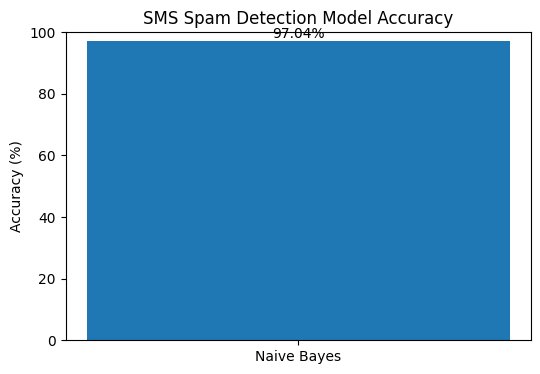

In [49]:
accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = accuracy * 100

plt.figure(figsize=(6,4))

plt.bar(
    ["Naive Bayes"],
    [accuracy_percentage]
)

plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.title("SMS Spam Detection Model Accuracy")

# Display the accuracy above the bar
plt.text(
    0,
    accuracy_percentage + 1,
    f"{accuracy_percentage:.2f}%",
    ha="center"
)

plt.show()


## 13. Project Results

The SMS Spam Detection project was developed using Python and Machine Learning.

The Multinomial Naive Bayes algorithm was used to classify messages as Spam or Not Spam. TF-IDF was used to convert text messages into numerical features.

The model achieved an accuracy of **97.04%** on the test dataset. The model was also tested with new sample messages to observe its predictions.

The results show that Machine Learning can be used to identify unwanted messages. However, the model may sometimes make incorrect predictions.